/tmp/ipykernel_605/3266679546.py:40: UserWarning: nperseg=1024 is greater than signal length max(len(x), len(y)) = 1000, using nperseg = 1000
  f, Pxx = signal.welch(senal, fs, nperseg=1024)


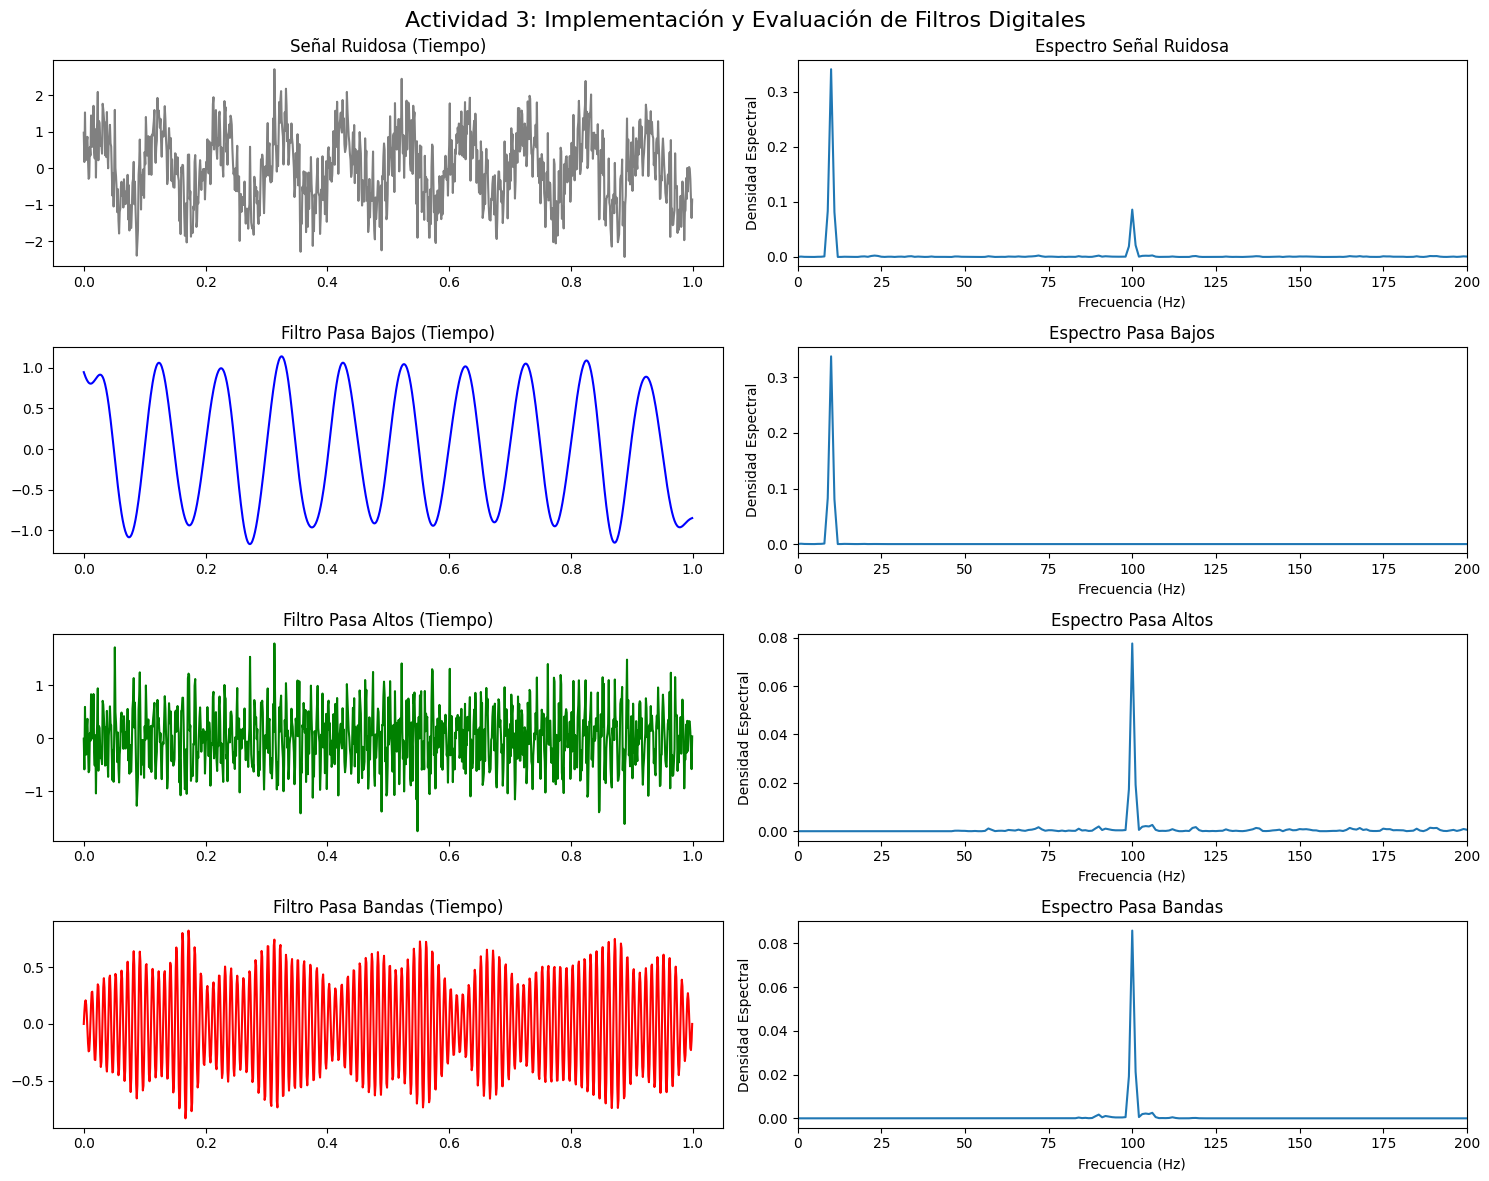

/tmp/ipykernel_605/3266679546.py:69: RuntimeWarning: divide by zero encountered in log10
  axs2[1].plot(w_hp/np.pi*nyq, 20*np.log10(abs(h_hp))); axs2[1].set_title('Respuesta Pasa Altos IIR')


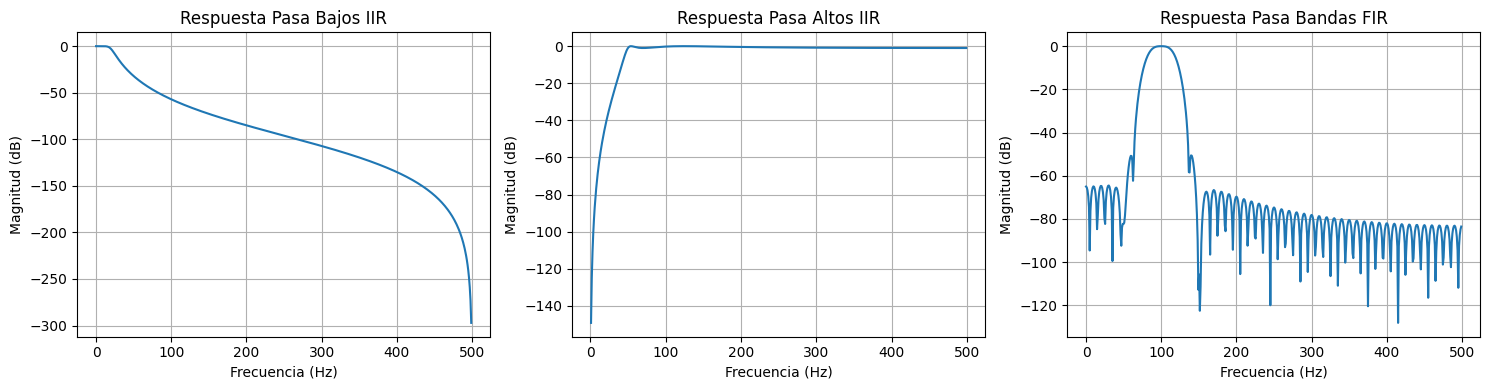

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# --- 1. DEFINICIÓN DE LA SEÑAL DE ENTRADA Y RUIDO ---
fs = 1000  # Frecuencia de muestreo (Hz)
t = np.linspace(0, 1, fs, endpoint=False)

# Señal compuesta: 10 Hz (útil) + 100 Hz (útil) + Ruido blanco
senal_util = np.sin(2 * np.pi * 10 * t) + 0.5 * np.sin(2 * np.pi * 100 * t)
ruido = np.random.normal(0, 0.5, len(t)) # Ruido blanco gaussiano
senal_ruidosa = senal_util + ruido

# --- 2. DISEÑO DE FILTROS (FIR e IIR) ---
# Frecuencias normalizadas (Nyquist = fs/2)
nyq = 0.5 * fs

# a) Filtro Pasa Bajos IIR (Butterworth) - Deja pasar < 20 Hz
b_lp, a_lp = signal.butter(4, 20 / nyq, btype='low')

# b) Filtro Pasa Altos IIR (Chebyshev) - Deja pasar > 50 Hz
b_hp, a_hp = signal.cheby1(4, 1, 50 / nyq, btype='high')

# c) Filtro Pasa Bandas FIR (Ventana Hamming) - Deja pasar entre 80 y 120 Hz
taps = 101
b_bp = signal.firwin(taps, [80 / nyq, 120 / nyq], pass_zero=False, window='hamming')

# --- 3. APLICACIÓN DE LOS FILTROS ---
# Usamos filtfilt para evitar desfase (fase cero)
senal_filtrada_lp = signal.filtfilt(b_lp, a_lp, senal_ruidosa)
senal_filtrada_hp = signal.filtfilt(b_hp, a_hp, senal_ruidosa)
senal_filtrada_bp = signal.filtfilt(b_bp, 1, senal_ruidosa) # FIR solo usa b

# --- 4. VISUALIZACIÓN DE RESULTADOS (Tiempo y Frecuencia) ---
fig, axs = plt.subplots(4, 2, figsize=(15, 12))
fig.suptitle('Actividad 3: Implementación y Evaluación de Filtros Digitales', fontsize=16)

# Función auxiliar para graficar espectros
def plot_espectro(ax, senal, titulo):
    f, Pxx = signal.welch(senal, fs, nperseg=1024)
    ax.plot(f, Pxx)
    ax.set_title(titulo); ax.set_xlabel('Frecuencia (Hz)'); ax.set_ylabel('Densidad Espectral')
    ax.set_xlim(0, 200)

# Fila 1: Señal Original con Ruido
axs[0, 0].plot(t, senal_ruidosa, color='gray'); axs[0, 0].set_title('Señal Ruidosa (Tiempo)')
plot_espectro(axs[0, 1], senal_ruidosa, 'Espectro Señal Ruidosa')

# Fila 2: Filtro Pasa Bajos
axs[1, 0].plot(t, senal_filtrada_lp, color='blue'); axs[1, 0].set_title('Filtro Pasa Bajos (Tiempo)')
plot_espectro(axs[1, 1], senal_filtrada_lp, 'Espectro Pasa Bajos')

# Fila 3: Filtro Pasa Altos
axs[2, 0].plot(t, senal_filtrada_hp, color='green'); axs[2, 0].set_title('Filtro Pasa Altos (Tiempo)')
plot_espectro(axs[2, 1], senal_filtrada_hp, 'Espectro Pasa Altos')

# Fila 4: Filtro Pasa Bandas
axs[3, 0].plot(t, senal_filtrada_bp, color='red'); axs[3, 0].set_title('Filtro Pasa Bandas (Tiempo)')
plot_espectro(axs[3, 1], senal_filtrada_bp, 'Espectro Pasa Bandas')

plt.tight_layout()
plt.show()

# --- 5. RESPUESTA EN FRECUENCIA DE LOS FILTROS ---
fig2, axs2 = plt.subplots(1, 3, figsize=(15, 4))
w_lp, h_lp = signal.freqz(b_lp, a_lp)
axs2[0].plot(w_lp/np.pi*nyq, 20*np.log10(abs(h_lp))); axs2[0].set_title('Respuesta Pasa Bajos IIR')
w_hp, h_hp = signal.freqz(b_hp, a_hp)
axs2[1].plot(w_hp/np.pi*nyq, 20*np.log10(abs(h_hp))); axs2[1].set_title('Respuesta Pasa Altos IIR')
w_bp, h_bp = signal.freqz(b_bp)
axs2[2].plot(w_bp/np.pi*nyq, 20*np.log10(abs(h_bp))); axs2[2].set_title('Respuesta Pasa Bandas FIR')
for ax in axs2:
    ax.set_xlabel('Frecuencia (Hz)'); ax.set_ylabel('Magnitud (dB)'); ax.grid()
plt.tight_layout()
plt.show()
